<a href="https://colab.research.google.com/github/narcelo90ff/repositorioDePython/blob/main/TrabalhoDePyhton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:


from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
CSV_NAME = 'Wholesale_customers_data.csv'

if not Path(CSV_NAME).exists():
    try:
        from google.colab import files
        print('Envie o arquivo Wholesale_customers_data.csv')
        files.upload()
    except Exception:
        pass

if not Path(CSV_NAME).exists():
    raise FileNotFoundError('Coloque Wholesale_customers_data.csv na pasta do notebook ou faça upload no Colab.')

df = pd.read_csv(CSV_NAME)
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
spending = df[features].astype(float)
print('Dimensão:', df.shape)
print('Valores ausentes:', int(df.isna().sum().sum()))
print('Linhas duplicadas:', int(df.duplicated().sum()))
print('Canal:', df['Channel'].value_counts().sort_index().to_dict())
print('Região:', df['Region'].value_counts().sort_index().to_dict())
assert len(df) == 440, 'A base esperada tem 440 linhas.'
assert df[features].isna().sum().sum() == 0, 'Há valores ausentes nas variáveis de gasto.'

Dimensão: (440, 8)
Valores ausentes: 0
Linhas duplicadas: 0
Canal: {1: 298, 2: 142}
Região: {1: 77, 2: 47, 3: 316}


Treino: (352, 6) | Teste: (88, 6)


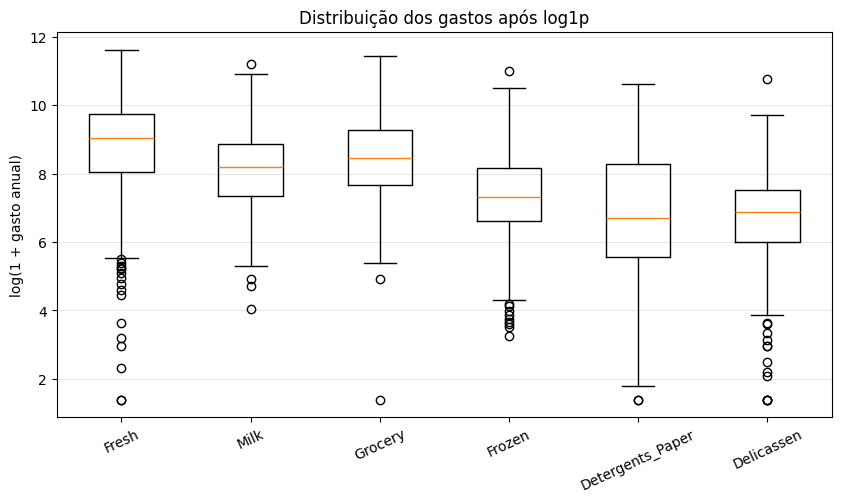

In [9]:
X_log = np.log1p(spending)
X_train_raw, X_test_raw = train_test_split(X_log, test_size=0.20, random_state=RANDOM_STATE)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
print('Treino:', X_train.shape, '| Teste:', X_test.shape)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([X_log[c] for c in features], tick_labels=features)
ax.set_title('Distribuição dos gastos após log1p')
ax.set_ylabel('log(1 + gasto anual)')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.3)
plt.show()

Melhor BIC:


,n_components,covariance_type,BIC,AIC,test_log_likelihood_mean,converged,iterations
2,3,full,5130.225538,4809.544151,-7.487196,True,9


Melhor AIC:


,n_components,covariance_type,BIC,AIC,test_log_likelihood_mean,converged,iterations
5,6,full,5354.516733,4709.290327,-8.05384,True,28


Melhor log-verossimilhança média no teste:


,n_components,covariance_type,BIC,AIC,test_log_likelihood_mean,converged,iterations
3,4,full,5177.059228,4748.196167,-7.397166,True,26


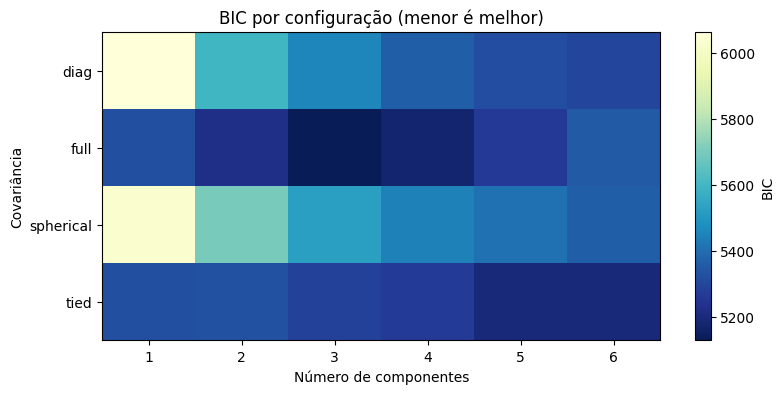

In [10]:
results = []
for covariance in ['full', 'tied', 'diag', 'spherical']:
    for k in range(1, 7):
        gm = GaussianMixture(
            n_components=k,
            covariance_type=covariance,
            random_state=RANDOM_STATE,
            n_init=10,
            reg_covar=1e-5,
            max_iter=1000
        )
        gm.fit(X_train)
        results.append({
            'n_components': k,
            'covariance_type': covariance,
            'BIC': gm.bic(X_train),
            'AIC': gm.aic(X_train),
            'test_log_likelihood_mean': gm.score(X_test),
            'converged': gm.converged_,
            'iterations': gm.n_iter_
        })

results = pd.DataFrame(results)
results.to_csv('comparacao_modelos.csv', index=False)
print('Melhor BIC:')
display(results.loc[[results['BIC'].idxmin()]])
print('Melhor AIC:')
display(results.loc[[results['AIC'].idxmin()]])
print('Melhor log-verossimilhança média no teste:')
display(results.loc[[results['test_log_likelihood_mean'].idxmax()]])

bic_pivot = results.pivot(index='covariance_type', columns='n_components', values='BIC')
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(bic_pivot.values, aspect='auto', cmap='YlGnBu_r')
ax.set_xticks(range(6), range(1, 7))
ax.set_yticks(range(4), bic_pivot.index)
ax.set_xlabel('Número de componentes')
ax.set_ylabel('Covariância')
ax.set_title('BIC por configuração (menor é melhor)')
fig.colorbar(im, ax=ax, label='BIC')
plt.show()

In [11]:
best_bic = results.loc[results['BIC'].idxmin()]
selected_k = int(best_bic['n_components'])
selected_cov = str(best_bic['covariance_type'])
print('Configuração selecionada:', selected_k, selected_cov)

scaler_all = StandardScaler()
X_all = scaler_all.fit_transform(X_log)
final_model = GaussianMixture(
    n_components=selected_k,
    covariance_type=selected_cov,
    random_state=RANDOM_STATE,
    n_init=20,
    reg_covar=1e-5,
    max_iter=1000
)
final_model.fit(X_all)
labels = final_model.predict(X_all)
probabilities = final_model.predict_proba(X_all)
result_df = df.copy()
result_df['cluster'] = labels
result_df.to_csv('clientes_com_cluster.csv', index=False)

print('Tamanho dos componentes:')
display(result_df['cluster'].value_counts().sort_index().rename('clientes').to_frame())
print('Pesos da mistura:', np.round(final_model.weights_, 4))
print('BIC no ajuste final:', round(final_model.bic(X_all), 2))
print('AIC no ajuste final:', round(final_model.aic(X_all), 2))
print('Log-verossimilhança média:', round(final_model.score(X_all), 4))
print('Silhouette complementar:', round(silhouette_score(X_all, labels), 4))
print('Probabilidade máxima média:', round(probabilities.max(axis=1).mean(), 4))
print('Clientes com probabilidade máxima < 0,70:', round((probabilities.max(axis=1) < .70).mean() * 100, 2), '%')

Configuração selecionada: 3 full
Tamanho dos componentes:


,clientes
cluster,
0,61
1,222
2,157


Pesos da mistura: [0.1586 0.4939 0.3475]
BIC no ajuste final: 6268.32
AIC no ajuste final: 5929.12
Log-verossimilhança média: -6.549
Silhouette complementar: 0.242
Probabilidade máxima média: 0.9306
Clientes com probabilidade máxima < 0,70: 6.36 %


Medianas por componente:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,2438.0,2713.0,4710.0,915.0,290.0,259.0
1,10724.5,1991.5,2466.5,2511.5,355.5,914.5
2,5626.0,7639.0,11532.0,993.0,4973.0,1371.0


Médias por componente:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,9287.4,4614.1,7583.0,2506.7,1869.4,1687.6
1,14584.3,2972.4,3244.7,4315.9,519.4,1261.1
2,9400.5,10248.6,14749.5,1532.6,6614.7,1834.6


Distribuição posterior por canal (análise posterior):


Channel,1,2
cluster,,
0,0.852,0.148
1,0.968,0.032
2,0.197,0.803


Distribuição posterior por região:


Region,1,2,3
cluster,,,
0,0.148,0.131,0.721
1,0.212,0.104,0.685
2,0.134,0.102,0.764


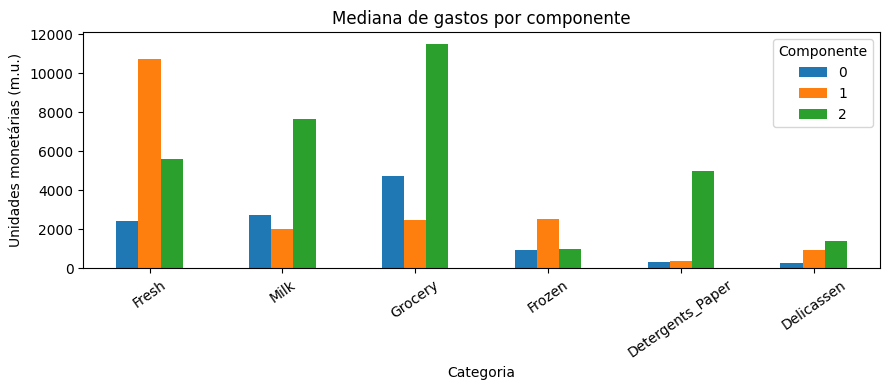

In [12]:
profile_median = result_df.groupby('cluster')[features].median().round(1)
profile_mean = result_df.groupby('cluster')[features].mean().round(1)
print('Medianas por componente:')
display(profile_median)
print('Médias por componente:')
display(profile_mean)

print('Distribuição posterior por canal (análise posterior):')
display(pd.crosstab(result_df['cluster'], result_df['Channel'], normalize='index').round(3))
print('Distribuição posterior por região:')
display(pd.crosstab(result_df['cluster'], result_df['Region'], normalize='index').round(3))

fig, ax = plt.subplots(figsize=(9, 4))
profile_median.T.plot(kind='bar', ax=ax)
ax.set_title('Mediana de gastos por componente')
ax.set_ylabel('Unidades monetárias (m.u.)')
ax.set_xlabel('Categoria')
ax.legend(title='Componente')
ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

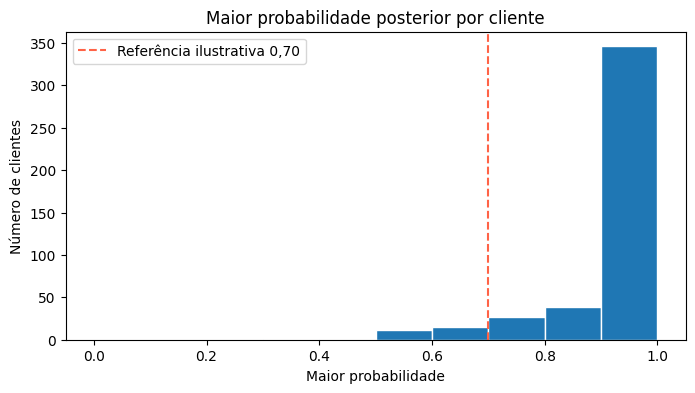

Cliente 177: cluster previsto=1, probabilidades=[0.339 0.368 0.293]
Cliente 275: cluster previsto=1, probabilidades=[0.201 0.503 0.296]
Cliente 344: cluster previsto=2, probabilidades=[0.491 0.    0.509]
Cliente 31: cluster previsto=1, probabilidades=[0.026 0.518 0.456]
Cliente 179: cluster previsto=0, probabilidades=[0.529 0.471 0.   ]


In [13]:

max_probability = probabilities.max(axis=1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(max_probability, bins=np.linspace(0, 1, 11), edgecolor='white')
ax.axvline(.70, color='tomato', linestyle='--', label='Referência ilustrativa 0,70')
ax.set_title('Maior probabilidade posterior por cliente')
ax.set_xlabel('Maior probabilidade')
ax.set_ylabel('Número de clientes')
ax.legend()
plt.show()

ambiguous = np.argsort(max_probability)[:5]
for idx in ambiguous:
    print(f'Cliente {idx+1}: cluster previsto={labels[idx]}, probabilidades={np.round(probabilities[idx], 3)}')

In [14]:
# Grupo 04 - GMM - script reproduzivel
# Requer: pandas, numpy, scikit-learn, matplotlib
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

CSV = Path("Wholesale_customers_data.csv")
if not CSV.exists(): raise FileNotFoundError("Coloque Wholesale_customers_data.csv ao lado deste script.")
df = pd.read_csv(CSV)
cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
Xlog = np.log1p(df[cols].astype(float))
Xtr_raw, Xte_raw = train_test_split(Xlog, test_size=0.20, random_state=42)
scaler = StandardScaler(); Xtr = scaler.fit_transform(Xtr_raw); Xte = scaler.transform(Xte_raw)
rows=[]
for cov in ["full", "tied", "diag", "spherical"]:
    for k in range(1,7):
        m=GaussianMixture(n_components=k,covariance_type=cov,random_state=42,n_init=10,reg_covar=1e-5,max_iter=1000).fit(Xtr)
        rows.append({"K":k,"covariance":cov,"BIC":m.bic(Xtr),"AIC":m.aic(Xtr),"test_loglik_mean":m.score(Xte)})
res=pd.DataFrame(rows); res.to_csv("comparacao_modelos.csv",index=False)
print("Melhor BIC\n",res.loc[[res.BIC.idxmin()]])
print("Melhor AIC\n",res.loc[[res.AIC.idxmin()]])
print("Melhor log-verossimilhanca de teste\n",res.loc[[res.test_loglik_mean.idxmax()]])
best=res.loc[res.BIC.idxmin()]
sc=StandardScaler(); Xa=sc.fit_transform(Xlog)
model=GaussianMixture(n_components=int(best.K),covariance_type=best.covariance,random_state=42,n_init=20,reg_covar=1e-5,max_iter=1000).fit(Xa)
labels=model.predict(Xa); probs=model.predict_proba(Xa)
out=df.copy(); out["cluster"]=labels; out.to_csv("clientes_com_cluster.csv",index=False)
print("Tamanhos\n",out.cluster.value_counts().sort_index())
print("Medianas\n",out.groupby("cluster")[cols].median().round(1))
print("Canal (análise posterior)\n",pd.crosstab(out.cluster,out.Channel,normalize="index").round(3))
print("BIC final",model.bic(Xa),"AIC final",model.aic(Xa),"Silhouette",silhouette_score(Xa,labels))


Melhor BIC
    K covariance          BIC          AIC  test_loglik_mean
2  3       full  5130.225538  4809.544151         -7.487196
Melhor AIC
    K covariance          BIC          AIC  test_loglik_mean
5  6       full  5354.516733  4709.290327          -8.05384
Melhor log-verossimilhanca de teste
    K covariance          BIC          AIC  test_loglik_mean
3  4       full  5177.059228  4748.196167         -7.397166
Tamanhos
 cluster
0     61
1    222
2    157
Name: count, dtype: int64
Medianas
            Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0         2438.0  2713.0   4710.0   915.0             290.0       259.0
1        10724.5  1991.5   2466.5  2511.5             355.5       914.5
2         5626.0  7639.0  11532.0   993.0            4973.0      1371.0
Canal (análise posterior)
 Channel      1      2
cluster              
0        0.852  0.148
1        0.968  0.032
2        0.197  0.803
B